## Задача

Собрать единый датасет собак и заполнений Mini C-BARQ из файлов Bohland и Serpell, пересчитать 42 пункта в 14 доменов и посмотреть, что в этих данных можно использовать дальше.

Одна строка — одно заполнение анкеты. В схеме есть идентификатор собаки, возраст в месяцах, пол, стерилизация, вес, порода, дата пристройства, сколько дней собака дома и ответы `q01`–`q42`. Анкеты полной C-BARQ (~100 пунктов) проецируются в те же 42 пункта и помечаются `instrument=full_mapped`.

## Первоисточники

Читать в этом порядке, если ноутбук виден впервые.

| Зачем | Страница |
|--------|----------|
| Что такое C-BARQ и зачем он Hvostun | [C-BARQ](../../../wiki/concepts/c-barq.md) |
| Как 42 пункта складываются в 14 доменов и почему пункты 27–28 разворачиваются | [скоринг Mini C-BARQ](../../../wiki/concepts/c-barq-short-42-scoring.md) |
| Зачем сводить разные выгрузки в одну таблицу | [data-harmonization](../../../wiki/concepts/data-harmonization.md) |
| Что именно собрано в этом ноутбуке: строки, волны, флаг `full_mapped` | [cbarq-mini-sessions-unified](../../../wiki/datasets/cbarq-mini-sessions-unified.md) |
| Откуда волны Bohland и почему «10 days» записаны как `d7` | [bohland-2023-shelter-adoption-cbarq](../../../wiki/datasets/bohland-2023-shelter-adoption-cbarq.md), [статья](../../../wiki/sources/bohland-2023-shelter-dog-behavior-ru.md) |
| Как пункты полной анкеты попадают в 42 | [c-barq-short-full-mapping](../../../QUESTS/c-barq-short-full-mapping.md) |

## Шаги

1. **Загрузка.** Прочитать CSV из `datasets` в отдельные таблицы.
2. **Единый датасет анкет.** Свести разные схемы полей к одной таблице `unified` и сохранить `cbarq_mini_sessions.csv`.
3. **14 доменов.** По формулам Mini C-BARQ посчитать субшкалы. Если по шкале заполнено меньше половины пунктов, значение остаётся пустым. Для Training difficulty пункты 27 и 28 разворачиваются (`4 − балл`). Результат — `domain_unified`.
4. **EDA.** На доменах: дубли только по 14 шкалам, затем полные дубли, пустые значения, выбросы, распределения и тепловые карты линейных связей. Очищенная таблица — `domain_dedup`. Волны одной и той же собаки дублем не считаются.


## Справка: скоринг Mini C-BARQ

The mini C-BARQ provides a set of quantitative scores for the following fourteen different subscales or categories of behavior:

- Excitability
- Stranger-directed aggression
- Owner-directed aggression 
- Dog-directed aggression
- Familiar dog aggression
- Stranger-directed fear
- Nonsocial fear
- Dog-directed fear
- Touch sensitivity 
- Separation-related behavior
- Attachment and attention-seeking
- Training difficulty
- Chasing
- Energy level

The mini C-BARQ also provides useful information on the occurrence of an additional 9 miscellaneous behavior problems ranging from escaping and roaming to persistent barking.

Each subscale is represented by a small number of 5-point scales (questions). Some are graduated scales that measure severity of particular behaviors (e.g. aggression) and are numbered from 0–4 in the questionnaire. The remainder are frequency scales which should be scored as: Never = 0, Seldom = 1, Sometimes = 2, Usually = 3 and Always = 4, except for questions 27 & 28 in Section 6. FOR THESE QUESTIONS ONLY, reverse the scores to: Never = 4, Seldom = 3, etc.

### To calculate behavior subscale scores, use the following formulae

- “Excitability” score = Sum of scores for questionnaire items 1 + 2 ÷ 2 (i.e. items 1 + 2)/2.

- “Stranger-directed aggression” score = (items 3 + 6 + 9)/3

- “Owner-directed aggression” score = (items 4 + 5 + 7)/3

- “Dog-directed aggression” score = (items 8 + 10)/2 

- “Dog rivalry/Familiar dog aggression” score = (items 11 + 12)/2

- “Stranger-directed fear” score= (items 13 + 15)/2

- “Nonsocial fear” score = (items 14 + 16 + 18)/3

- “Dog-directed fear” score = (items 17 + 19)/2

- “Touch sensitivity” score = (items 20 + 21)/2

- “Separation-related problems” score = (items 22 + 23 + 24)/3

- “Attachment/attention-seeking” score = (items  25 + 26)/2

- “Training difficulty” score = (items 27 + 28 + 29)/3 — remember to reverse scoring order for items 27 & 28 (see above).

- “Chasing” score = (items 30 + 31)/2

- “Energy” score = (items 39 + 40)/2

- “Miscellaneous” items other than those listed above are optional, and can be removed from the questionnaire as desired. If retained, they should be scored individually, 0–4.






© James A. Serpell & The University of Pennsylvania, 


## 1. Загрузка данных

Все CSV из `datasets`: Bohland (S4 и листы собак) и вложения Serpell (mini, post-adoption, full и online).


In [1]:
from pathlib import Path

import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=pd.errors.ParserWarning)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)

DATA_DIR = Path("../datasets")
BOHLAND_DIR = DATA_DIR / "journal.pone.0289356"
SERPELL_DIR = DATA_DIR / "Attachments_serpell@vet.upenn.edu_2026-09-29_22-07-31"

In [2]:
def load_csv(path: Path) -> pd.DataFrame:
    """Load CSV trying ; then , (Excel exports often use ';')."""
    for sep in (";", ","):
        try:
            df = pd.read_csv(path, sep=sep, encoding="utf-8", engine="python", on_bad_lines="warn")
        except UnicodeDecodeError:
            df = pd.read_csv(path, sep=sep, encoding="latin1", engine="python", on_bad_lines="warn")
        # reject unsplit single-column reads
        if df.shape[1] == 1 and (";" in str(df.columns[0]) or "," in str(df.columns[0])):
            continue
        return df
    raise ValueError(f"Could not parse CSV: {path}")


def make_key(path: Path) -> str:
    rel = path.relative_to(DATA_DIR).with_suffix("")
    s = str(rel)
    s = s.replace("Attachments_serpell@vet.upenn.edu_2026-09-29_22-07-31", "serpell")
    s = s.replace("journal.pone.0289356/journal.pone.0289356.", "bohland/")
    s = s.replace("journal.pone.0289356", "bohland")
    return (
        s.replace(" ", "_")
        .replace("-", "_")
        .replace("/", "__")
        .replace("(", "")
        .replace(")", "")
    )


csv_paths = sorted(DATA_DIR.rglob("*.csv"))
skip_paths = sorted(DATA_DIR.rglob("*.docx"))

dfs: dict[str, pd.DataFrame] = {}
for path in csv_paths:
    key = make_key(path)
    dfs[key] = load_csv(path)

inventory = pd.DataFrame(
    [
        {
            "key": key,
            "rows": df.shape[0],
            "cols": df.shape[1],
            "path": str(path.relative_to(DATA_DIR)),
        }
        for path, key in zip(csv_paths, [make_key(p) for p in csv_paths])
        for df in [dfs[key]]
    ]
).sort_values("key")

print(f"Loaded {len(dfs)} CSV → dfs['...']")
if skip_paths:
    print("Skipped (not tabular):")
    for p in skip_paths:
        print(" -", p.relative_to(DATA_DIR))
inventory

Loaded 18 CSV → dfs['...']
Skipped (not tabular):
 - Attachments_serpell@vet.upenn.edu_2026-09-29_22-07-31/C-BARQ100scoring.docx
 - Attachments_serpell@vet.upenn.edu_2026-09-29_22-07-31/Mini C-BARQscoring.docx


,key,rows,cols,path
9,bohland__Sheet1_2_Tаблица_1,105,13,journal.pone.0289356/Sheet1 (2)-Tаблица 1.csv
10,bohland__Sheet1_3_Tаблица_1,99,13,journal.pone.0289356/Sheet1 (3)-Tаблица 1.csv
11,bohland__Sheet1_Tаблица_1,101,13,journal.pone.0289356/Sheet1-Tаблица 1.csv
12,bohland__s003,137,16,journal.pone.0289356/journal.pone.0289356.s003...
13,bohland__s004,505,553,journal.pone.0289356/journal.pone.0289356.s004...
0,serpell__2009_06_19_Adopting_Owners_complete__...,24,120,Attachments_serpell@vet.upenn.edu_2026-09-29_2...
1,serpell__2009_06_19_Adopting_Owners_complete__...,1,120,Attachments_serpell@vet.upenn.edu_2026-09-29_2...
2,serpell__2009_06_19_Adopting_Owners_complete__...,6,120,Attachments_serpell@vet.upenn.edu_2026-09-29_2...
3,serpell__2009_07_17_Shelter_Study_Complete__Ca...,198,68,Attachments_serpell@vet.upenn.edu_2026-09-29_2...
4,serpell__2009_07_17_Shelter_Study_Complete__Co...,85,69,Attachments_serpell@vet.upenn.edu_2026-09-29_2...


In [3]:
# Удобные алиасы основных таблиц
bohland_s4 = dfs["bohland__s004"]
bohland_s3 = dfs["bohland__s003"]
bohland_sheet1 = dfs["bohland__Sheet1_Tаблица_1"]
bohland_sheet1_2 = dfs["bohland__Sheet1_2_Tаблица_1"]
bohland_sheet1_3 = dfs["bohland__Sheet1_3_Tаблица_1"]

serpell_post_adoption_mini = dfs["serpell__PostAdoptionMiniCBARQ_Deidentified"]
serpell_adopting_online = dfs["serpell__Adopting_owners_cbarq_online"]

serpell_shelter_ca = dfs["serpell__2009_07_17_Shelter_Study_Complete__California_Tаблица_1"]
serpell_shelter_co = dfs["serpell__2009_07_17_Shelter_Study_Complete__Colorado_Tаблица_1"]
serpell_shelter_mo = dfs["serpell__2009_07_17_Shelter_Study_Complete__Missouri_Tаблица_1"]
serpell_shelter_orphan = dfs["serpell__2009_07_17_Shelter_Study_Complete__Orphan_Dogs_Tаблица_1"]

serpell_owners_ca = dfs["serpell__2009_06_19_Adopting_Owners_complete__California_Tаблица_1"]
serpell_owners_co = dfs["serpell__2009_06_19_Adopting_Owners_complete__Colorado_Tаблица_1"]
serpell_owners_mo = dfs["serpell__2009_06_19_Adopting_Owners_complete__Missouri_Tаблица_1"]

(list(dfs.keys()))

['serpell__2009_06_19_Adopting_Owners_complete__California_Tаблица_1',
 'serpell__2009_06_19_Adopting_Owners_complete__Colorado_Tаблица_1',
 'serpell__2009_06_19_Adopting_Owners_complete__Missouri_Tаблица_1',
 'serpell__2009_07_17_Shelter_Study_Complete__California_Tаблица_1',
 'serpell__2009_07_17_Shelter_Study_Complete__Colorado_Tаблица_1',
 'serpell__2009_07_17_Shelter_Study_Complete__Missouri_Tаблица_1',
 'serpell__2009_07_17_Shelter_Study_Complete__Orphan_Dogs_Tаблица_1',
 'serpell__Adopting_owners_cbarq_online',
 'serpell__PostAdoptionMiniCBARQ_Deidentified',
 'bohland__Sheet1_2_Tаблица_1',
 'bohland__Sheet1_3_Tаблица_1',
 'bohland__Sheet1_Tаблица_1',
 'bohland__s003',
 'bohland__s004',
 'unified__cbarq_mini_sessions',
 'unified__domain_dedup',
 'unified__domain_unified',
 'unified__qc_by_source']

## 2. Единый датасет анкет

Код ниже самодостаточен: не импортирует `src/unify_cbarq.py`.
Запускать после ячеек с `DATA_DIR`. Одна строка = одно заполнение.
Full (~100) → `q01`–`q42`, флаг `instrument=full_mapped`.
Результат: `datasets/unified/cbarq_mini_sessions.csv`.


In [4]:
import re

# DATA_DIR / SERPELL_DIR / BOHLAND_DIR — из ячейки импортов
OUT_DIR = DATA_DIR / "unified"

LB_TO_KG = 0.45359237

# short item -> full item numbers. Multiple full items are merged with max.
SHORT_FROM_FULL: dict[int, list[int]] = {
    1: [66],
    2: [67],
    3: [10],
    4: [13],
    5: [17],
    6: [18],
    7: [19],
    8: [23, 24],
    9: [20],
    10: [29],
    11: [34],
    12: [35],
    13: [36],
    14: [38],
    15: [40],
    16: [42],
    17: [45],
    18: [47],
    19: [54],
    20: [49],
    21: [50],
    22: [57],
    23: [58, 59],
    24: [61],
    25: [70],
    26: [71],
    27: [2],
    28: [3],
    29: [7],
    30: [76],
    31: [77],
    32: [78],
    33: [81],
    34: [86],
    35: [87],
    36: [89],
    37: [90],
    38: [91],
    39: [92],
    40: [93],
    41: [96],
    42: [98],
}

Q_COLS = [f"q{i:02d}" for i in range(1, 43)]

META_COLS = [
    "session_id",
    "dog_id",
    "source",
    "instrument",
    "is_mapped",
    "wave",
    "survey_date",
    "adopted_date",
    "age_months",
    "sex",
    "neutered",
    "weight_kg",
    "breed",
    "shelter",
    "raw_dog_id",
    "notes",
    "n_answered",
]

SCHEMA_COLS = META_COLS[:8] + ["days_at_home", "age_months", "sex", "neutered", "weight_kg", "breed"] + Q_COLS + [
    "n_answered",
    "shelter",
    "raw_dog_id",
    "notes",
]

# Mini C-BARQ item order as stored in Bohland S4 (wave 0, no suffix).
BOHLAND_Q_BASES = [
    "Just before being taken for a walk:",
    "Just before being taken on a car trip:",
    "When approached directly by an unfamiliar person while being walked/exercised on a leash:",
    "When toys, bones or other objects are taken away by a household member:",
    "When approached directly by a household member while s/he (the dog) is eating:",
    "When mailmen or other delivery workers approach your home:",
    "When his/her food is taken away by a household member:",
    "When approached directly by an unfamiliar dog while being walked/exercised on a leash:",
    "When strangers walk past your home when your dog is outside or in the yard:",
    "When barked, growled, or lunged at by another (unfamiliar) dog:",
    "When approached while eating by another (familiar) household dog (leave blank if no other dogs):",
    "When approached while playing with/chewing a favorite toy, bone, object, etc., by another (familiar) household dog (leave blank if no other dogs):",
    "When approached directly by an unfamiliar person while away from your home:",
    "In response to sudden or loud noises (e.g. thunder, vacuum cleaner, car backfire, road drills, objects being dropped, etc.):",
    "When an unfamiliar person tries to touch or pet the dog:",
    "In response to strange or unfamiliar objects on or near the sidewalk (e.g. plastic trash bags, leaves, litter, flags flapping, etc.",
    "When approached directly by an unfamiliar dog",
    "When first exposed to unfamiliar situations (e.g. first car trip, first time in elevator, first visit to veterinarian, etc.)",
    "When barked, growled, or lunged at by an unfamiliar dog:",
    "When having nails clipped by a household member:",
    "When groomed or bathed by a household member:",
    "Restlessness/agitation/pacing:",
    "Barking or whining:",
    "Chewing/scratching at doors, floor, windows, curtains, etc:",
    "Tends to follow you (or other members of the household) about the house, from room to room:",
    "Tends to sit close to, or in contact with, you (or others) when you are sitting down:",
    "Obeys a 'sit' command immediately:",
    "Obeys a 'stay' command immediately:",
    "Easily distracted by interesting sights, sounds or smells:",
    "Chases or would chase birds, given the chance:",
    "Chases or would chase squirrels, rabbits, etc., given the chance:",
    "Escapes or would escape from home or yard, given the chance:",
    "Chews inappropriate objects:",
    "Pulls excessively hard when on the leash:",
    "Urinates against objects/ furnishings in your home:",
    "Urinates when left alone at night, or during the daytime:",
    "Defecates when left alone at night, or during the daytime:",
    "Hyperactive, restless, has trouble settling down:",
    "Playful, puppyish, boisterous:",
    "Active, energetic, always on the go:",
    "Chases own tail/hind end:",
    "Barks persistently when alarmed or excited:",
]

# event, column suffix, wave label, survey-date column
BOHLAND_WAVES = [
    ("10 days after adoption", "", "d7", "Date/Time Completed:"),
    ("30 days after adoption", ".1", "d30", "Date/Time Completed:.1"),
    ("3 months after adoption", ".2", "d90", "Date/Time Completed:.2"),
    ("6 months after adoption", ".3", "d180", "Date/Time Completed:.3"),
]

FREQ = {
    "never": 0.0,
    "seldom": 1.0,
    "sometimes": 2.0,
    "usually": 3.0,
    "always": 4.0,
    "нет, никогда": 0.0,
    "редко": 1.0,
    "иногда": 2.0,
    "обычно": 3.0,
    "всегда": 4.0,
}

RU_MONTHS = [
    ("янв", 1),
    ("фев", 2),
    ("мар", 3),
    ("апр", 4),
    ("мая", 5),
    ("май", 5),
    ("июн", 6),
    ("июл", 7),
    ("авг", 8),
    ("сен", 9),
    ("окт", 10),
    ("ноя", 11),
    ("дек", 12),
]

FULL_COL_RE = re.compile(
    r"^(?:tra|agg|fear|sep|exc|att|mis|attach|excit|train|misc)(\d+)$",
    re.IGNORECASE,
)
MINI_COL_RE = re.compile(r"^(?:exc|agg|fear|sep|att|tra|mis)(\d+)$", re.IGNORECASE)
POST_STEM_RE = re.compile(
    r"^(?:excit|agg|fear|sep|attach|train|misc)(\d+)_s(\d+)$",
    re.IGNORECASE,
)

MAPPED_NOTE = "full→mini; q08=max(full 23,24); q23=max(full 58,59)"
ONLINE_NOTE = (
    MAPPED_NOTE
    + "; source file already reverses full items 5–7; q29=full 7 is stored reversed"
)
BOHLAND_NOTE = "weight assumed lb→kg; age years→months; 10-day wave labeled d7"


def load_csv(path: Path, **kwargs) -> pd.DataFrame:
    """Load a CSV that may be ';' (Excel) or ',' separated."""
    header = kwargs.pop("header", "infer")
    for sep in (";", ","):
        try:
            df = pd.read_csv(
                path,
                sep=sep,
                encoding="utf-8",
                engine="python",
                on_bad_lines="warn",
                header=header,
            )
        except UnicodeDecodeError:
            df = pd.read_csv(
                path,
                sep=sep,
                encoding="latin1",
                engine="python",
                on_bad_lines="warn",
                header=header,
            )
        if df.shape[1] == 1 and (";" in str(df.columns[0]) or "," in str(df.columns[0])):
            continue
        return df
    raise ValueError(f"Could not parse CSV: {path}")


def _blank(value) -> bool:
    if value is None or (isinstance(value, float) and pd.isna(value)):
        return True
    text = str(value).strip()
    return text in {"", ".", "nan", "None", "NA", "N/A", "na", "-"}


def to_float(value) -> float | None:
    if _blank(value):
        return None
    text = str(value).strip().replace(",", ".")
    text = text.split("=")[0].strip()
    try:
        return float(text)
    except ValueError:
        return None


def parse_score(value) -> float | None:
    if _blank(value):
        return None
    text = str(value).strip()
    key = text.lower()
    if key in FREQ:
        return FREQ[key]
    number = to_float(text)
    if number is None:
        return None
    if 0 <= number <= 4:
        return float(number)
    return None


def parse_sex(value) -> str | None:
    if _blank(value):
        return None
    key = str(value).strip().lower()
    if key in {"m", "male", "мальчик"}:
        return "male"
    if key in {"f", "female", "девочка"}:
        return "female"
    return None


def parse_bool(value) -> bool | None:
    if _blank(value):
        return None
    key = str(value).strip().lower()
    if key in {"yes", "y", "true", "1", "да", "sterilized", "neutered", "spayed"}:
        return True
    if key in {"no", "n", "false", "0", "нет", "intact"}:
        return False
    return None


def parse_date(value) -> pd.Timestamp | None:
    if _blank(value):
        return None
    text = str(value).strip()
    match = re.match(r"(\d{1,2})-([A-Za-zА-Яа-яё.]+)-(\d{2,4})", text)
    if match:
        day = int(match.group(1))
        token = match.group(2).lower().strip(".")
        year = int(match.group(3))
        month = next((num for prefix, num in RU_MONTHS if token.startswith(prefix)), None)
        if month is not None:
            if year < 100:
                year += 2000 if year < 30 else 1900
            return pd.Timestamp(year=year, month=month, day=day)
    parsed = pd.to_datetime(text, errors="coerce", dayfirst=False)
    if pd.isna(parsed):
        return None
    return pd.Timestamp(parsed).normalize()


def age_from_parts(months, years) -> float | None:
    month_value = to_float(months)
    year_value = to_float(years)
    if month_value is not None and month_value > 0:
        return month_value
    if year_value is not None and year_value >= 0:
        return year_value * 12
    if month_value is not None:
        return month_value
    return None


def pounds_to_kg(value) -> float | None:
    number = to_float(value)
    if number is None:
        return None
    return round(number * LB_TO_KG, 3)


def norm_id(value) -> str | None:
    if _blank(value):
        return None
    text = str(value).strip()
    if text.endswith(".0"):
        text = text[:-2]
    if text in {"0"}:
        return None
    return text


def col_lookup(columns: list[str], *candidates: str) -> str | None:
    lowered = {str(c).strip().lower(): c for c in columns}
    for name in candidates:
        hit = lowered.get(name.strip().lower())
        if hit is not None:
            return hit
    return None


def empty_record() -> dict:
    row = {col: None for col in SCHEMA_COLS}
    row["is_mapped"] = False
    row["n_answered"] = 0
    return row


def finalize(rows: list[dict]) -> pd.DataFrame:
    if not rows:
        return pd.DataFrame(columns=SCHEMA_COLS)
    frame = pd.DataFrame(rows)
    for col in Q_COLS:
        frame[col] = pd.to_numeric(frame[col], errors="coerce")
    frame["n_answered"] = frame[Q_COLS].notna().sum(axis=1).astype(int)
    frame = frame.loc[frame["n_answered"] > 0].copy()
    frame["survey_date"] = pd.to_datetime(frame["survey_date"], errors="coerce")
    frame["adopted_date"] = pd.to_datetime(frame["adopted_date"], errors="coerce")
    days = (frame["survey_date"] - frame["adopted_date"]).dt.days
    frame["days_at_home"] = days.where(days >= 0)
    frame["age_months"] = pd.to_numeric(frame["age_months"], errors="coerce")
    frame["weight_kg"] = pd.to_numeric(frame["weight_kg"], errors="coerce")
    frame["is_mapped"] = frame["is_mapped"].astype(bool)
    frame["wave"] = frame["wave"].where(frame["wave"].notna(), None)
    wave_token = frame["wave"].fillna("na").astype(str)
    frame["session_id"] = frame["source"].astype(str) + ":" + frame["dog_id"].astype(str) + ":" + wave_token
    # disambiguate rare collisions
    dup = frame["session_id"].duplicated(keep=False)
    if dup.any():
        frame.loc[dup, "session_id"] = frame.loc[dup, "session_id"] + "#" + frame.loc[dup].groupby("session_id").cumcount().astype(str)
    return frame[SCHEMA_COLS].reset_index(drop=True)


def project_full_scores(scores: dict[int, float | None]) -> dict[str, float | None]:
    projected: dict[str, float | None] = {}
    for short, full_items in SHORT_FROM_FULL.items():
        values = [scores.get(item) for item in full_items]
        present = [value for value in values if value is not None]
        projected[f"q{short:02d}"] = max(present) if present else None
    return projected


def full_scores_from_row(row: pd.Series) -> dict[int, float | None]:
    scores: dict[int, float | None] = {}
    for column, value in row.items():
        match = FULL_COL_RE.match(str(column).strip())
        if not match:
            continue
        scores[int(match.group(1))] = parse_score(value)
    return scores


def mini_scores_from_numbered(row: pd.Series) -> dict[str, float | None]:
    scores = {col: None for col in Q_COLS}
    for column, value in row.items():
        match = MINI_COL_RE.match(str(column).strip())
        if not match:
            continue
        number = int(match.group(1))
        if 1 <= number <= 42:
            scores[f"q{number:02d}"] = parse_score(value)
    return scores


def _demo_common(row: pd.Series, columns: list[str]) -> dict:
    month_col = col_lookup(columns, "Age (in months)")
    year_col = col_lookup(columns, "Age (in years)")
    sex_col = col_lookup(columns, "Sex")
    neuter_col = col_lookup(columns, "Spay/Neuter", "Spay/neuter", "IsNeutered")
    weight_col = col_lookup(columns, "Weight (in pounds)", "Weight")
    breed_col = col_lookup(columns, "Breed", "BreedID")
    shelter_col = col_lookup(columns, "Shelter", "shelter")
    return {
        "age_months": age_from_parts(
            row[month_col] if month_col else None,
            row[year_col] if year_col else None,
        ),
        "sex": parse_sex(row[sex_col]) if sex_col else None,
        "neutered": parse_bool(row[neuter_col]) if neuter_col else None,
        "weight_kg": pounds_to_kg(row[weight_col]) if weight_col else None,
        "breed": None if not breed_col or _blank(row[breed_col]) else str(row[breed_col]).strip(),
        "shelter": None if not shelter_col or _blank(row[shelter_col]) else str(row[shelter_col]).strip(),
    }


def transform_shelter() -> pd.DataFrame:
    folder = SERPELL_DIR / "2009_07_17_Shelter_Study_Complete"
    rows: list[dict] = []
    for path in sorted(folder.glob("*.csv")):
        frame = load_csv(path)
        columns = list(frame.columns)
        id_col = col_lookup(columns, "ID#")
        for _, raw in frame.iterrows():
            record = empty_record()
            raw_id = norm_id(raw[id_col]) if id_col else None
            demo = _demo_common(raw, columns)
            shelter = demo["shelter"] or path.stem.split("-")[0]
            record.update(demo)
            record.update(
                {
                    "dog_id": f"{shelter}:{raw_id or 'unknown'}",
                    "source": "serpell_shelter_2009",
                    "instrument": "mini",
                    "is_mapped": False,
                    "wave": None,
                    "raw_dog_id": raw_id,
                    "notes": None,
                }
            )
            record.update(mini_scores_from_numbered(raw))
            rows.append(record)
    return finalize(rows)


def transform_postadoption() -> pd.DataFrame:
    path = SERPELL_DIR / "PostAdoptionMiniCBARQ-Deidentified.csv"
    frame = load_csv(path)
    rows: list[dict] = []
    for index, raw in frame.iterrows():
        adoption = parse_date(raw.get("AdoptionDate"))
        by_wave: dict[str, dict[str, float | None]] = {}
        for column, value in raw.items():
            match = POST_STEM_RE.match(str(column).strip())
            if not match:
                continue
            item = int(match.group(1))
            wave = f"S{match.group(2)}"
            if not 1 <= item <= 42:
                continue
            by_wave.setdefault(wave, {col: None for col in Q_COLS})
            by_wave[wave][f"q{item:02d}"] = parse_score(value)
        for wave, scores in sorted(by_wave.items()):
            survey_col = f"SurveyDate{wave[-1]}"
            record = empty_record()
            record.update(
                {
                    "dog_id": f"postmini_{int(index):03d}",
                    "source": "serpell_postadoption_mini",
                    "instrument": "mini",
                    "is_mapped": False,
                    "wave": wave,
                    "survey_date": parse_date(raw.get(survey_col)) if survey_col in frame.columns else None,
                    "adopted_date": adoption,
                    "raw_dog_id": None,
                    "notes": "deidentified; no stable external dog id or demographics",
                }
            )
            record.update(scores)
            rows.append(record)
    return finalize(rows)


def transform_owners_full() -> pd.DataFrame:
    folder = SERPELL_DIR / "2009_06_19_Adopting_Owners_complete"
    rows: list[dict] = []
    for path in sorted(folder.glob("*.csv")):
        frame = load_csv(path)
        columns = list(frame.columns)
        id_col = col_lookup(columns, "ID#")
        for _, raw in frame.iterrows():
            record = empty_record()
            raw_id = norm_id(raw[id_col]) if id_col else None
            demo = _demo_common(raw, columns)
            shelter = demo["shelter"] or path.stem.split("-")[0]
            record.update(demo)
            record.update(
                {
                    "dog_id": f"{shelter}:{raw_id or 'unknown'}",
                    "source": "serpell_owners_full",
                    "instrument": "full_mapped",
                    "is_mapped": True,
                    "wave": None,
                    "raw_dog_id": raw_id,
                    "notes": MAPPED_NOTE,
                }
            )
            record.update(project_full_scores(full_scores_from_row(raw)))
            rows.append(record)
    return finalize(rows)


def transform_online_full() -> pd.DataFrame:
    path = SERPELL_DIR / "Adopting_owners_cbarq_online.csv"
    frame = load_csv(path, header=2)
    columns = list(frame.columns)
    rows: list[dict] = []
    for _, raw in frame.iterrows():
        record = empty_record()
        raw_id = norm_id(raw.get("DogID"))
        age = to_float(raw.get("AgeAtEvaluation"))
        if age is None:
            birthday = parse_date(raw.get("Birthday"))
            if birthday is not None:
                # no survey date in this export; age relative to file year 2009
                age = (pd.Timestamp("2009-07-17") - birthday).days / 30.437
        shelter = None if _blank(raw.get("shelter")) else str(raw.get("shelter")).strip()
        breed = None if _blank(raw.get("BreedID")) else str(raw.get("BreedID")).strip()
        record.update(
            {
                "dog_id": f"{shelter or 'NA'}:{raw_id or 'unknown'}",
                "source": "serpell_online_full",
                "instrument": "full_mapped",
                "is_mapped": True,
                "wave": None,
                "age_months": age,
                "sex": parse_sex(raw.get("Sex")),
                "neutered": parse_bool(raw.get("IsNeutered")),
                "weight_kg": pounds_to_kg(raw.get("Weight")),
                "breed": breed,
                "shelter": shelter,
                "raw_dog_id": raw_id,
                "notes": ONLINE_NOTE,
            }
        )
        record.update(project_full_scores(full_scores_from_row(raw)))
        rows.append(record)
    return finalize(rows)


def _bohland_demo() -> pd.DataFrame:
    sheet = load_csv(BOHLAND_DIR / "Sheet1 (3)-Tаблица 1.csv")
    sheet = sheet.copy()
    sheet["animal_key"] = sheet["Animal_ID"].map(norm_id)
    sheet = sheet.dropna(subset=["animal_key"]).drop_duplicates("animal_key", keep="first")
    return sheet.set_index("animal_key")


def transform_bohland() -> pd.DataFrame:
    frame = load_csv(BOHLAND_DIR / "journal.pone.0289356.s004.csv")
    demo = _bohland_demo()
    consent = frame.loc[frame["Event Name"] == "Consent Form"].copy()
    consent["animal_key"] = consent["Animal ID"].map(norm_id)
    consent_by_record = consent.drop_duplicates("Record ID").set_index("Record ID")

    rows: list[dict] = []
    for event, suffix, wave, date_col in BOHLAND_WAVES:
        block = frame.loc[frame["Event Name"] == event]
        for _, raw in block.iterrows():
            record_id = raw["Record ID"]
            consent_row = consent_by_record.loc[record_id] if record_id in consent_by_record.index else None
            animal_key = None if consent_row is None else consent_row["animal_key"]
            sheet_row = demo.loc[animal_key] if animal_key in demo.index else None
            shelter_name_col = "Dog shelter name: " if suffix == "" else f"Dog shelter name: {suffix}"
            shelter_name = None
            if shelter_name_col in frame.columns and not _blank(raw.get(shelter_name_col)):
                shelter_name = str(raw.get(shelter_name_col)).strip()
            age_months = None
            sex = None
            weight_kg = None
            breed = None
            shelter = shelter_name
            if sheet_row is not None:
                age_years = to_float(sheet_row.get("Age"))
                age_months = None if age_years is None else age_years * 12
                sex = parse_sex(sheet_row.get("Sex"))
                weight_kg = pounds_to_kg(sheet_row.get("Weight"))
                breed = None if _blank(sheet_row.get("Breed")) else str(sheet_row.get("Breed")).strip()
                if not _blank(sheet_row.get("Shelter")):
                    shelter = str(sheet_row.get("Shelter")).strip()
            adoption = None
            if consent_row is not None:
                adoption = parse_date(consent_row.get("Date of adoption:  "))
            record = empty_record()
            record.update(
                {
                    "dog_id": f"rec{record_id}",
                    "source": "bohland_2023",
                    "instrument": "mini",
                    "is_mapped": False,
                    "wave": wave,
                    "survey_date": parse_date(raw.get(date_col)) if date_col in frame.columns else None,
                    "adopted_date": adoption,
                    "age_months": age_months,
                    "sex": sex,
                    "neutered": None,
                    "weight_kg": weight_kg,
                    "breed": breed,
                    "shelter": shelter,
                    "raw_dog_id": animal_key,
                    "notes": BOHLAND_NOTE,
                }
            )
            for index, base in enumerate(BOHLAND_Q_BASES, start=1):
                column = base if suffix == "" else f"{base}{suffix}"
                record[f"q{index:02d}"] = parse_score(raw[column]) if column in frame.columns else None
            rows.append(record)
    return finalize(rows)


def build_unified() -> pd.DataFrame:
    parts = [
        transform_shelter(),
        transform_postadoption(),
        transform_owners_full(),
        transform_online_full(),
        transform_bohland(),
    ]
    unified = pd.concat(parts, ignore_index=True)
    unified = unified[SCHEMA_COLS]
    return unified


def qc_summary(frame: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for source, part in frame.groupby("source", dropna=False):
        rows.append(
            {
                "source": source,
                "rows": len(part),
                "dogs": part["dog_id"].nunique(),
                "instrument": part["instrument"].iloc[0] if len(part) else None,
                "pct_age": round(100 * part["age_months"].notna().mean(), 1),
                "pct_sex": round(100 * part["sex"].notna().mean(), 1),
                "pct_neutered": round(100 * part["neutered"].notna().mean(), 1),
                "pct_weight": round(100 * part["weight_kg"].notna().mean(), 1),
                "pct_adopted_date": round(100 * part["adopted_date"].notna().mean(), 1),
                "pct_days_at_home": round(100 * part["days_at_home"].notna().mean(), 1),
                "pct_breed": round(100 * part["breed"].notna().mean(), 1),
                "mean_n_answered": round(part["n_answered"].mean(), 1),
            }
        )
    return pd.DataFrame(rows).sort_values("source").reset_index(drop=True)


def export(frame: pd.DataFrame | None = None) -> Path:
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    if frame is None:
        frame = build_unified()
    csv_path = OUT_DIR / "cbarq_mini_sessions.csv"
    frame.to_csv(csv_path, index=False)
    try:
        frame.to_parquet(OUT_DIR / "cbarq_mini_sessions.parquet", index=False)
    except Exception:
        pass
    summary = qc_summary(frame)
    summary.to_csv(OUT_DIR / "qc_by_source.csv", index=False)
    return csv_path




In [5]:
unified = build_unified()
export_path = export(unified)
print(export_path)
print("rows", len(unified), "duplicate session_id", int(unified["session_id"].duplicated().sum()))

qc_summary(unified)


../datasets/unified/cbarq_mini_sessions.csv
rows 956 duplicate session_id 0


,source,rows,dogs,instrument,pct_age,pct_sex,pct_neutered,pct_weight,pct_adopted_date,pct_days_at_home,pct_breed,mean_n_answered
0,bohland_2023,337,104,mini,91.4,92.6,0.0,92.0,100.0,99.7,92.6,40.0
1,serpell_online_full,21,21,full_mapped,100.0,100.0,95.2,100.0,0.0,0.0,100.0,35.7
2,serpell_owners_full,31,31,full_mapped,100.0,100.0,100.0,90.3,0.0,0.0,100.0,39.5
3,serpell_postadoption_mini,123,66,mini,0.0,0.0,0.0,0.0,91.9,91.9,0.0,37.4
4,serpell_shelter_2009,444,444,mini,99.1,100.0,100.0,77.0,0.0,0.0,96.6,40.6


## 3. Домены C-BARQ


In [6]:
# 14 субшкал Mini C-BARQ. Среднее по непустым пунктам.
# Если заполнено меньше половины пунктов субшкалы — значение пустое.
# Пункты 27 и 28 для Training difficulty: 4 − сырой балл. Пункты вне субшкал — отдельные misc_*.

SUBSCALES = {
    "excitability": [1, 2],
    "stranger_directed_aggression": [3, 6, 9],
    "owner_directed_aggression": [4, 5, 7],
    "dog_directed_aggression": [8, 10],
    "familiar_dog_aggression": [11, 12],
    "stranger_directed_fear": [13, 15],
    "nonsocial_fear": [14, 16, 18],
    "dog_directed_fear": [17, 19],
    "touch_sensitivity": [20, 21],
    "separation_related_problems": [22, 23, 24],
    "attachment_attention_seeking": [25, 26],
    "training_difficulty": [27, 28, 29],
    "chasing": [30, 31],
    "energy": [39, 40],
}
MISC_ITEMS = [32, 33, 34, 35, 36, 37, 38, 41, 42]
REVERSE_ITEMS = {27, 28}

META_KEEP = [
    "session_id", "dog_id", "source", "instrument", "is_mapped", "wave",
    "survey_date", "adopted_date", "days_at_home", "age_months", "sex",
    "neutered", "weight_kg", "breed", "shelter", "raw_dog_id",
]

scores = unified.copy()
for item in REVERSE_ITEMS:
    col = f"q{item:02d}"
    scores[col] = scores[col].where(scores[col].isna(), 4 - scores[col])

domain_unified = scores[META_KEEP].copy()
for name, items in SUBSCALES.items():
    cols = [f"q{item:02d}" for item in items]
    block = scores[cols]
    answered = block.notna().sum(axis=1)
    value = block.mean(axis=1, skipna=True).round(2)
    domain_unified[name] = value.where(answered >= len(cols) / 2)
for item in MISC_ITEMS:
    domain_unified[f"misc_{item:02d}"] = scores[f"q{item:02d}"]

domain_path = DATA_DIR / "unified" / "domain_unified.csv"
domain_unified.to_csv(domain_path, index=False)
print(domain_path)
print(domain_unified.shape)


../datasets/unified/domain_unified.csv
(956, 39)


In [7]:
domain_unified.head(40)

,session_id,dog_id,source,instrument,is_mapped,wave,survey_date,adopted_date,days_at_home,age_months,...,energy,misc_32,misc_33,misc_34,misc_35,misc_36,misc_37,misc_38,misc_41,misc_42
0,serpell_shelter_2009:CA:15578:na,CA:15578,serpell_shelter_2009,mini,False,None,NaT,NaT,NaN,16.0,...,2.5,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,2.0
1,serpell_shelter_2009:CA:15579:na,CA:15579,serpell_shelter_2009,mini,False,None,NaT,NaT,NaN,16.0,...,3.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,2.0
2,serpell_shelter_2009:CA:19422:na,CA:19422,serpell_shelter_2009,mini,False,None,NaT,NaT,NaN,19.0,...,2.5,0.0,0.0,1.0,1.0,0.0,0.0,0.0,3.0,3.0
3,serpell_shelter_2009:CA:21519:na,CA:21519,serpell_shelter_2009,mini,False,None,NaT,NaT,NaN,23.0,...,2.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4,serpell_shelter_2009:CA:22427:na,CA:22427,serpell_shelter_2009,mini,False,None,NaT,NaT,NaN,12.0,...,4.0,2.0,1.0,2.0,0.0,0.0,0.0,2.0,3.0,2.0
5,serpell_shelter_2009:CA:22429:na,CA:22429,serpell_shelter_2009,mini,False,None,NaT,NaT,NaN,84.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,serpell_shelter_2009:CA:22450:na,CA:22450,serpell_shelter_2009,mini,False,None,NaT,NaT,NaN,20.0,...,2.0,0.0,0.0,2.0,0.0,0.0,0.0,1.0,0.0,0.0
7,serpell_shelter_2009:CA:22502:na,CA:22502,serpell_shelter_2009,mini,False,None,NaT,NaT,NaN,48.0,...,3.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0
8,serpell_shelter_2009:CA:22544:na,CA:22544,serpell_shelter_2009,mini,False,None,NaT,NaT,NaN,8.0,...,4.0,0.0,4.0,4.0,0.0,0.0,0.0,2.0,3.0,4.0
9,serpell_shelter_2009:CA:22609:na,CA:22609,serpell_shelter_2009,mini,False,None,NaT,NaT,NaN,14.0,...,2.5,0.0,1.0,3.0,0.0,0.0,0.0,0.0,3.0,3.0


## 4. EDA

Дубли по 14 субшкалам, затем полные дубли, пустые значения, выбросы, распределения и тепловые карты. Исходный `domain_unified` не перезаписывается. Графики — по `domain_dedup`.


### 4.1 Дубли по 14 шкалам

Одинаковый вектор субшкал. Разные волны одной собаки не считаются дублем. Совпадение при пропусках считается отдельно: pandas приравнивает NaN к NaN.


In [8]:

SCALE_COLS = [
    "excitability",
    "stranger_directed_aggression",
    "owner_directed_aggression",
    "dog_directed_aggression",
    "familiar_dog_aggression",
    "stranger_directed_fear",
    "nonsocial_fear",
    "dog_directed_fear",
    "touch_sensitivity",
    "separation_related_problems",
    "attachment_attention_seeking",
    "training_difficulty",
    "chasing",
    "energy",
]
SHOW_COLS = ["source", "dog_id", "wave", "session_id", "instrument", "days_at_home"]

def scale_duplicate_groups(frame: pd.DataFrame, label: str) -> pd.DataFrame:
    """Groups with identical 14 subscale vectors. NaN matches NaN."""
    if frame.empty:
        print(f"{label}: rows 0")
        return frame.iloc[0:0].assign(group_size=0, dup_kind="")
    sizes = frame.groupby(SCALE_COLS, dropna=False)["session_id"].transform("size")
    grouped = frame.loc[sizes > 1].copy()
    print(f"{label}: rows {len(frame)}, extra scale-duplicates {int(frame.duplicated(SCALE_COLS).sum())}, rows in groups {len(grouped)}")
    if grouped.empty:
        return grouped.assign(group_size=[], dup_kind=[])
    grouped["group_size"] = grouped.groupby(SCALE_COLS, dropna=False)["session_id"].transform("size")
    n_dogs = grouped.groupby(SCALE_COLS, dropna=False)["dog_id"].transform("nunique")
    n_waves = grouped.groupby(SCALE_COLS, dropna=False)["wave"].transform(lambda s: s.fillna("__na__").nunique())
    grouped["dup_kind"] = np.where(
        (n_dogs == 1) & (n_waves > 1),
        "same_dog_waves",
        "drop_candidate",
    )
    return grouped.sort_values(["dup_kind", "dog_id", "wave"])

complete_mask = domain_unified[SCALE_COLS].notna().all(axis=1)
scale_dups_complete = scale_duplicate_groups(domain_unified.loc[complete_mask], "all 14 scales filled")
scale_dups_missing = scale_duplicate_groups(domain_unified.loc[~complete_mask], "at least one scale missing")
scale_dups = pd.concat([scale_dups_complete, scale_dups_missing], ignore_index=True)
print("same_dog_waves", int((scale_dups["dup_kind"] == "same_dog_waves").sum()) if len(scale_dups) else 0)
print("drop_candidate rows", int((scale_dups["dup_kind"] == "drop_candidate").sum()) if len(scale_dups) else 0)
scale_dups[SHOW_COLS + ["group_size", "dup_kind"]]


all 14 scales filled: rows 582, extra scale-duplicates 2, rows in groups 4
at least one scale missing: rows 374, extra scale-duplicates 1, rows in groups 2
same_dog_waves 0
drop_candidate rows 6


,source,dog_id,wave,session_id,instrument,days_at_home,group_size,dup_kind
0,serpell_shelter_2009,CA:33471,None,serpell_shelter_2009:CA:33471:na,mini,NaN,2,drop_candidate
1,serpell_shelter_2009,CA:33472,None,serpell_shelter_2009:CA:33472:na,mini,NaN,2,drop_candidate
2,serpell_shelter_2009,MO:453427,None,serpell_shelter_2009:MO:453427:na,mini,NaN,2,drop_candidate
3,serpell_shelter_2009,MO:453429,None,serpell_shelter_2009:MO:453429:na,mini,NaN,2,drop_candidate
4,serpell_shelter_2009,CA:30565,None,serpell_shelter_2009:CA:30565:na,mini,NaN,2,drop_candidate
5,serpell_shelter_2009,CA:30566,None,serpell_shelter_2009:CA:30566:na,mini,NaN,2,drop_candidate


### 4.2 Полные дубли

Все колонки, кроме `session_id`. В `domain_dedup` снимаются полные дубли и кандидаты прошлого шага (не волны одной собаки).


In [9]:

full_cols = [c for c in domain_unified.columns if c != "session_id"]
full_dup_mask = domain_unified.duplicated(full_cols, keep=False)
full_dups = domain_unified.loc[full_dup_mask].sort_values(full_cols)
print("full duplicate rows (all columns except session_id):", int(full_dup_mask.sum()))
print("extra full duplicates:", int(domain_unified.duplicated(full_cols).sum()))

drop_idx = set()
if len(scale_dups):
    candidates = scale_dups.loc[scale_dups["dup_kind"] == "drop_candidate"]
    # keep the first session of each identical 14-scale profile
    if len(candidates):
        keyed = domain_unified.loc[domain_unified["session_id"].isin(candidates["session_id"])]
        drop_idx.update(keyed.duplicated(SCALE_COLS, keep="first").pipe(lambda m: keyed.index[m]).tolist())
full_extra = domain_unified.duplicated(full_cols, keep="first")
drop_idx.update(domain_unified.index[full_extra].tolist())

domain_dedup = domain_unified.drop(index=list(drop_idx)).copy()
print("removed", len(domain_unified) - len(domain_dedup), "rows;", "domain_dedup", len(domain_dedup))
dedup_path = DATA_DIR / "unified" / "domain_dedup.csv"
domain_dedup.to_csv(dedup_path, index=False)
print(dedup_path)
full_dups[SHOW_COLS] if len(full_dups) else domain_dedup.head(0)


full duplicate rows (all columns except session_id): 0
extra full duplicates: 0
removed 3 rows; domain_dedup 953
../datasets/unified/domain_dedup.csv


,session_id,dog_id,source,instrument,is_mapped,wave,survey_date,adopted_date,days_at_home,age_months,...,energy,misc_32,misc_33,misc_34,misc_35,misc_36,misc_37,misc_38,misc_41,misc_42


### 4.3 Пустые значения

Срезы `source` × `wave` × `instrument` на `domain_dedup`. `misc_*` только как доля пропусков, строки из-за них не удаляются.


In [10]:

null_rate = domain_dedup[SCALE_COLS].isna().mean().sort_values(ascending=False).rename("pct_null")
print("share of empty subscales")
display_null = (null_rate * 100).round(1).to_frame()

any_null = domain_dedup[SCALE_COLS].isna().any(axis=1)
by_slice = (
    domain_dedup.assign(any_null=any_null)
    .groupby(["source", "wave", "instrument"], dropna=False)["any_null"]
    .agg(rows="size", rows_with_null="sum", pct_with_null="mean")
    .reset_index()
)
by_slice["pct_with_null"] = (by_slice["pct_with_null"] * 100).round(1)

worst = null_rate.idxmax()
worst_slice = (
    domain_dedup.assign(scale_null=domain_dedup[worst].isna())
    .groupby(["source", "wave", "instrument"], dropna=False)["scale_null"]
    .agg(rows="size", empty="sum", pct_empty="mean")
    .reset_index()
    .sort_values("pct_empty", ascending=False)
)
worst_slice["pct_empty"] = (worst_slice["pct_empty"] * 100).round(1)
print("leakiest subscale:", worst)

n_empty = domain_dedup[SCALE_COLS].isna().sum(axis=1)
print("empty subscales per row:\n", n_empty.value_counts().sort_index().to_string())
examples = domain_dedup.loc[n_empty == n_empty.max(), ["source", "dog_id", "wave", "session_id"]].copy()
examples["n_empty_scales"] = n_empty.max()
if "unified" in globals() and "n_answered" in unified.columns:
    examples["n_answered"] = examples["session_id"].map(unified.set_index("session_id")["n_answered"])
misc_cols = [c for c in domain_dedup.columns if c.startswith("misc_")]
print("misc empty share, %:", (domain_dedup[misc_cols].isna().mean() * 100).round(1).to_dict())
display_null, by_slice, worst_slice, examples.head(15)


share of empty subscales
leakiest subscale: familiar_dog_aggression
empty subscales per row:
 0     580
1     279
2      51
3      17
4      12
5       4
6       2
7       2
9       3
10      1
13      2
misc empty share, %: {'misc_32': 5.1, 'misc_33': 1.5, 'misc_34': 2.0, 'misc_35': 1.6, 'misc_36': 4.0, 'misc_37': 4.8, 'misc_38': 1.0, 'misc_41': 1.5, 'misc_42': 1.4}


(                              pct_null
 familiar_dog_aggression           30.0
 touch_sensitivity                  8.2
 separation_related_problems        3.7
 dog_directed_fear                  3.5
 chasing                            3.4
 dog_directed_aggression            3.0
 stranger_directed_aggression       2.0
 training_difficulty                1.9
 nonsocial_fear                     1.4
 owner_directed_aggression          1.3
 stranger_directed_fear             1.2
 attachment_attention_seeking       0.9
 energy                             0.9
 excitability                       0.5,
                       source  wave   instrument  rows  rows_with_null  \
 0               bohland_2023  d180         mini    81              31   
 1               bohland_2023   d30         mini    82              40   
 2               bohland_2023    d7         mini    99              48   
 3               bohland_2023   d90         mini    75              31   
 4        serpell_online_full

### 4.4 Выбросы

Границы `Q1 − 1.5·IQR` и `Q3 + 1.5·IQR` внутри шкалы 0–4. Строки не удаляются.


In [11]:

bounds_rows = []
outlier_flags = pd.DataFrame(index=domain_dedup.index)
for col in SCALE_COLS:
    series = domain_dedup[col]
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flag = series.notna() & ((series < low) | (series > high))
    outlier_flags[col] = flag
    bounds_rows.append({
        "scale": col,
        "n": int(series.notna().sum()),
        "q1": round(q1, 2),
        "q3": round(q3, 2),
        "iqr": round(iqr, 2),
        "low": round(low, 2),
        "high": round(high, 2),
        "n_out": int(flag.sum()),
        "pct_out": round(100 * flag.mean(), 1),
    })
iqr_table = pd.DataFrame(bounds_rows).sort_values("n_out", ascending=False)
outlier_rows = domain_dedup.loc[outlier_flags.any(axis=1), ["source", "dog_id", "wave", "session_id"]].copy()
outlier_rows["scales"] = outlier_flags.loc[outlier_rows.index].apply(lambda r: ", ".join(r.index[r]), axis=1)
print("rows with at least one IQR outlier:", len(outlier_rows), "(not removed)")
iqr_table, outlier_rows.head(20)


rows with at least one IQR outlier: 245 (not removed)


(                           scale    n    q1    q3   iqr   low  high  n_out  \
 2      owner_directed_aggression  941  0.00  0.33  0.33 -0.50  0.82    113   
 5         stranger_directed_fear  942  0.00  1.00  1.00 -1.50  2.50     46   
 13                        energy  944  2.00  3.00  1.00  0.50  4.50     25   
 4        familiar_dog_aggression  667  0.00  1.00  1.00 -1.50  2.50     24   
 7              dog_directed_fear  920  0.00  1.50  1.50 -2.25  3.75     21   
 6                 nonsocial_fear  940  0.33  1.33  1.00 -1.17  2.83     20   
 11           training_difficulty  935  1.33  2.33  1.00 -0.17  3.83     15   
 1   stranger_directed_aggression  934  0.00  1.33  1.33 -2.00  3.32     14   
 10  attachment_attention_seeking  944  2.50  3.50  1.00  1.00  5.00     14   
 9    separation_related_problems  918  0.33  1.67  1.34 -1.68  3.68     13   
 8              touch_sensitivity  875  0.00  1.50  1.50 -2.25  3.75     11   
 0                   excitability  948  1.50  3.00  

### 4.5 Распределения


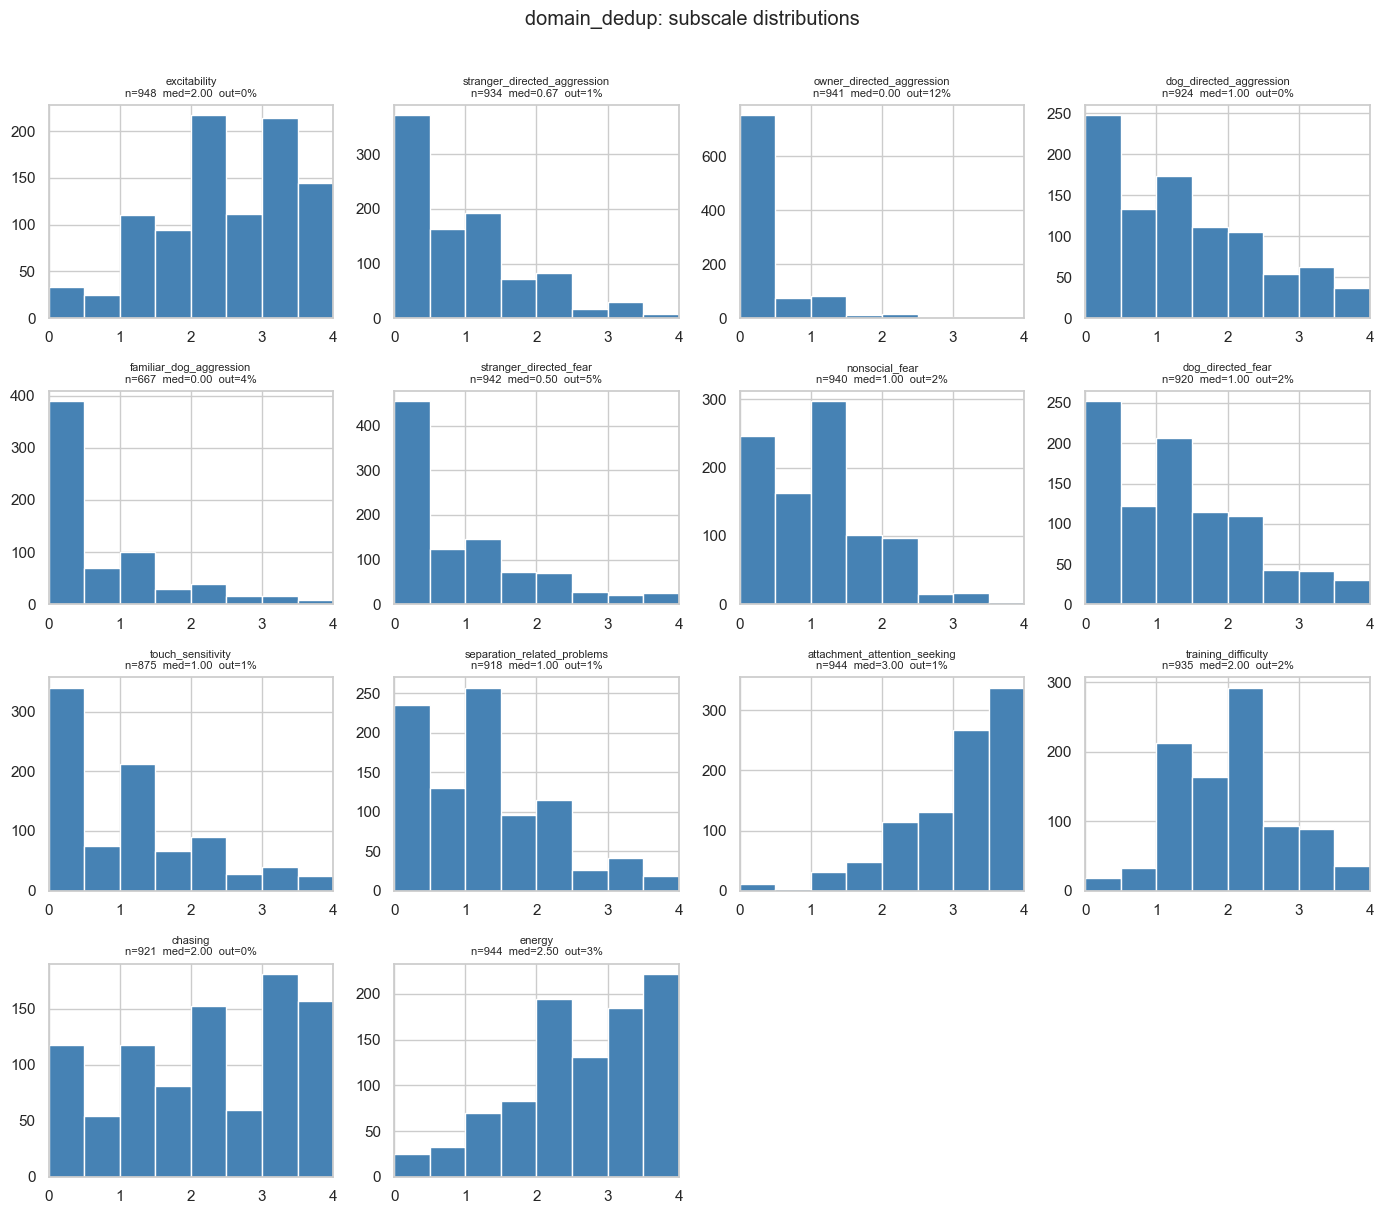

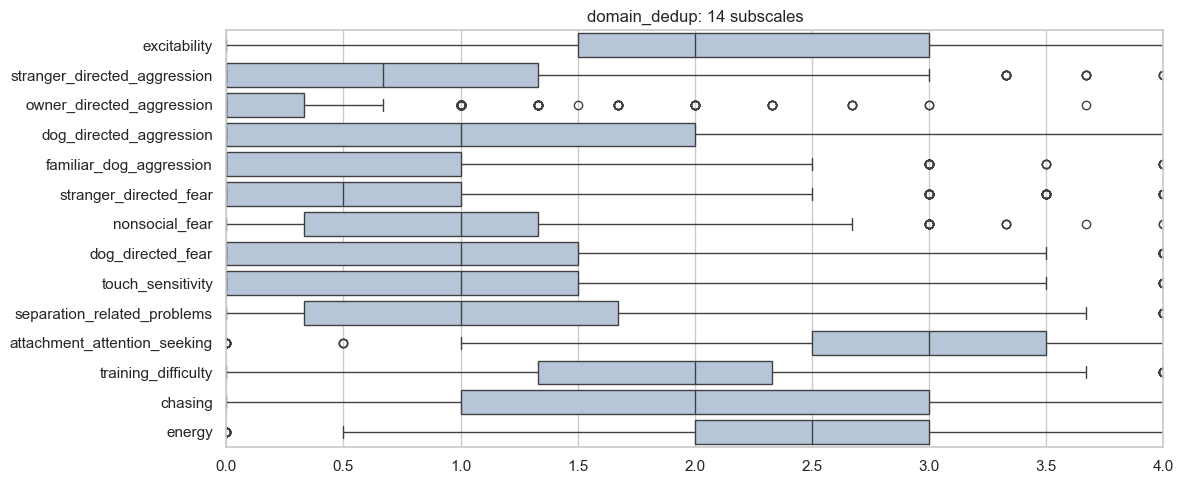

In [12]:

fig, axes = plt.subplots(4, 4, figsize=(14, 12))
axes = axes.ravel()
for ax, col in zip(axes, SCALE_COLS):
    series = domain_dedup[col].dropna()
    ax.hist(series, bins=np.linspace(0, 4, 9), color="steelblue", edgecolor="white")
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    pct_out = 100 * ((series < low) | (series > high)).mean() if len(series) else 0
    ax.set_xlim(0, 4)
    ax.set_title(f"{col}\nn={len(series)}  med={series.median():.2f}  out={pct_out:.0f}%", fontsize=8)
for ax in axes[len(SCALE_COLS):]:
    ax.axis("off")
fig.suptitle("domain_dedup: subscale distributions", y=1.01)
fig.tight_layout()

fig2, ax2 = plt.subplots(figsize=(12, 5))
sns.boxplot(data=domain_dedup[SCALE_COLS], orient="h", ax=ax2, color="lightsteelblue")
ax2.set_xlim(0, 4)
ax2.set_title("domain_dedup: 14 subscales")
fig2.tight_layout()


### 4.6 Линейные зависимости

Пара считается только по строкам, где обе шкалы заполнены (`min_periods=20`).


,method,a,b,r
0,pearson,stranger_directed_aggression,dog_directed_aggression,0.59
1,pearson,stranger_directed_fear,nonsocial_fear,0.53
2,spearman,stranger_directed_aggression,dog_directed_aggression,0.58
3,spearman,stranger_directed_fear,nonsocial_fear,0.50


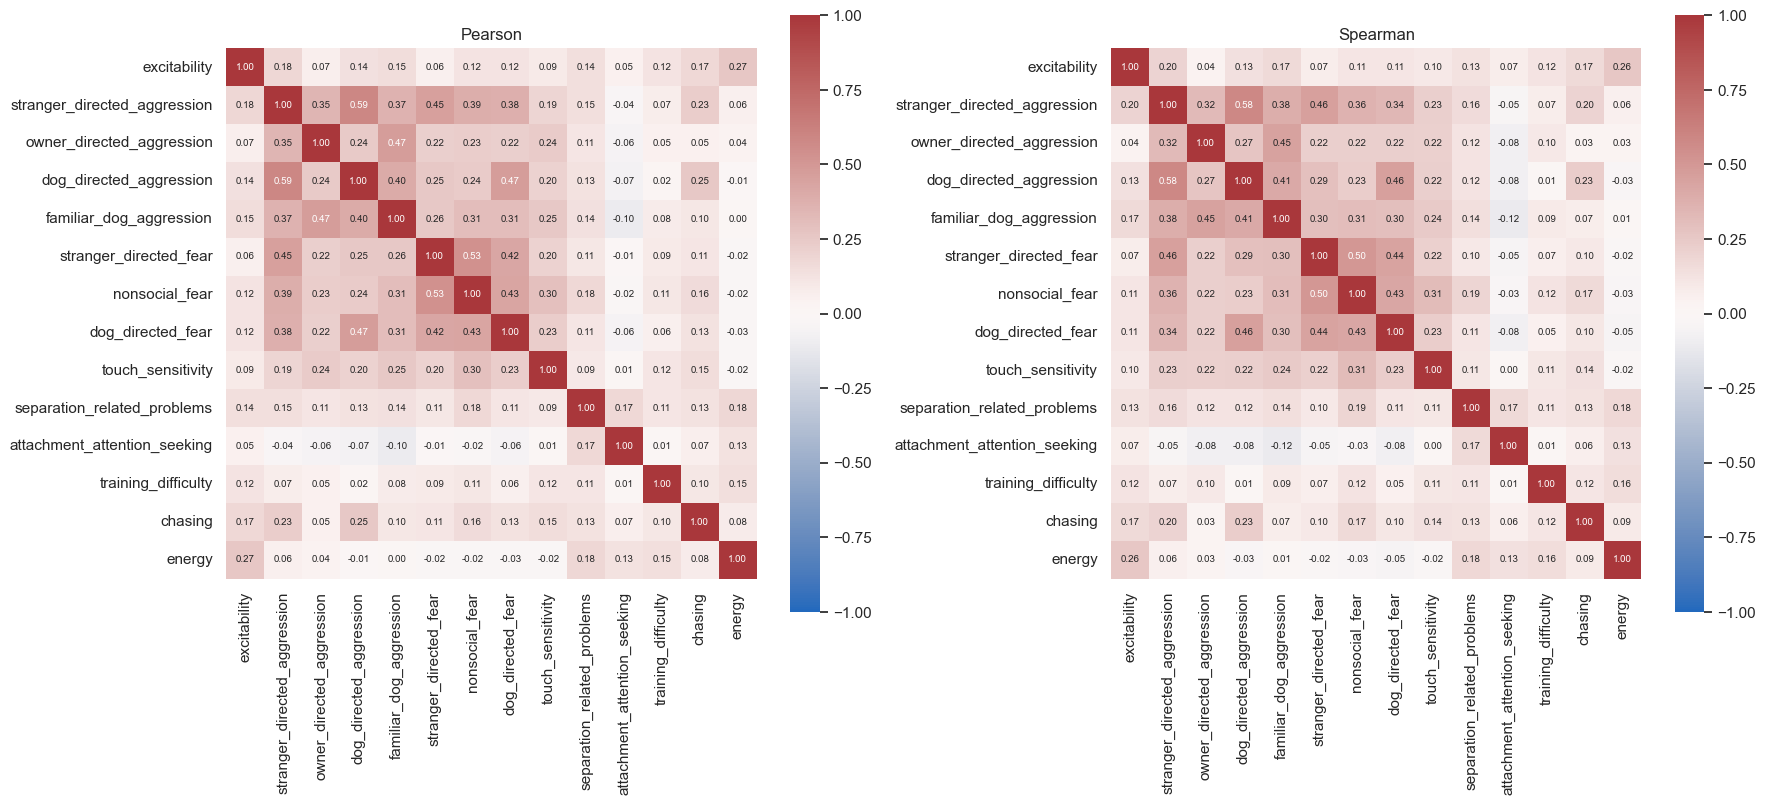

In [13]:

pearson = domain_dedup[SCALE_COLS].corr(method="pearson", min_periods=20)
spearman = domain_dedup[SCALE_COLS].corr(method="spearman", min_periods=20)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, matrix, title in (
    (axes[0], pearson, "Pearson"),
    (axes[1], spearman, "Spearman"),
):
    sns.heatmap(
        matrix,
        ax=ax,
        vmin=-1,
        vmax=1,
        cmap="vlag",
        annot=True,
        fmt=".2f",
        annot_kws={"size": 7},
        square=True,
    )
    ax.set_title(title)
fig.tight_layout()

pairs = []
for method, matrix in (("pearson", pearson), ("spearman", spearman)):
    for i, left in enumerate(SCALE_COLS):
        for right in SCALE_COLS[i + 1:]:
            value = matrix.loc[left, right]
            if pd.notna(value) and abs(value) >= 0.5:
                pairs.append({"method": method, "a": left, "b": right, "r": round(float(value), 2)})
strong_pairs = pd.DataFrame(pairs)
if len(strong_pairs):
    strong_pairs = strong_pairs.sort_values(["method", "r"], ascending=[True, False])
strong_pairs
